In [24]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
from numba import njit
from scipy.ndimage import convolve, generate_binary_structure
import utils as ut

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Here I reproduce a result from this paper to validate my computation of structure factor of the Ising model.

In [25]:
# utils.py contains metropolis algorithm for periodic boundary conditions
# this paper uses free boundary conditions

def get_energy(lattice, H=0.0):
    horizontal = -np.sum(lattice[:, :-1] * lattice[:, 1:])
    vertical = -np.sum(lattice[:-1, :] * lattice[1:, :])
    field = -H * lattice.sum()

    return horizontal + vertical + field

@njit 
def metropolis(lattice, steps, BJ, H, energy, save_every=None):

    L = lattice.shape[0]

    if save_every is not None:
        n_frames = steps // save_every + 1
        frames = np.empty((n_frames, L, L), dtype=np.int8)
        frames[0] = lattice
        frame_idx = 1
    else:
        frames = None

    lattice = lattice.copy()
    net_spin = lattice.sum()

    for t in range(0, steps):
        x = np.random.randint(0,L)
        y = np.random.randint(0,L)

        spin = lattice[x,y]

        neighbour_sum = 0
        if x > 0:
            neighbour_sum += lattice[x - 1, y]
        if x < L - 1:
            neighbour_sum += lattice[x + 1, y]
        if y > 0:
            neighbour_sum += lattice[x, y - 1]
        if y < L - 1:
            neighbour_sum += lattice[x, y + 1]

        dE = 2 * spin * (neighbour_sum + H)

        if dE <= 0 or np.random.random() < np.exp(-BJ * dE):
            lattice[x, y] *= -1
            energy += dE
            net_spin -= 2 * spin
        
        if save_every is not None and (t+1) % save_every == 0:
            frames[frame_idx] = lattice
            frame_idx += 1
            
    return lattice, energy, frames

def structure_factor(lattice):
    spin_k = np.fft.fft2(lattice)
    S_k = np.abs(spin_k)**2

    return np.fft.fftshift(S_k)


In [26]:
ratio = 1 # paper starts from an ordered lattice
H = 0.0 # H = mu_s * B / J
BJ = 0.4407 # critical temperature
num_sweeps = 500000  # each lattice was assigned different num_sweeps in original paper but highest was 5e6

Ls = [12, 18, 24, 30, 48, 60]
burn_in_fraction = 0.1
save_every = 20 # sweeps

In [27]:
all_frames = []

for L in Ls:
    N = L**2
    steps = N * num_sweeps

    burn_in_steps = int(burn_in_fraction * steps)
    equilibration_steps = steps - burn_in_steps

    save_every_steps = save_every * N

    lattice = ut.generate_lattice(L, ratio)
    energy = get_energy(lattice, H)

    # burn-in
    lattice, energy, _ = metropolis(lattice, burn_in_steps, BJ, H, energy)

    # measurement
    _, _, frames = metropolis(lattice, equilibration_steps, BJ, H, energy, save_every_steps)
    all_frames.append(frames)

    print(f"Completed L = {L}")


Completed L = 12
Completed L = 18
Completed L = 24
Completed L = 30
Completed L = 48
Completed L = 60


In [28]:
mean_S_axes = []

for frames in all_frames:
    L = frames.shape[1]
    centre = L // 2

    S_axes = []

    for frame in frames:
        S_k = structure_factor(frame)

        # ky = 0, vary kx
        S_axis = S_k[centre, :]
        S_axes.append(S_axis)

    mean_S_axis = np.mean(S_axes, axis=0)
    mean_S_axes.append(mean_S_axis)

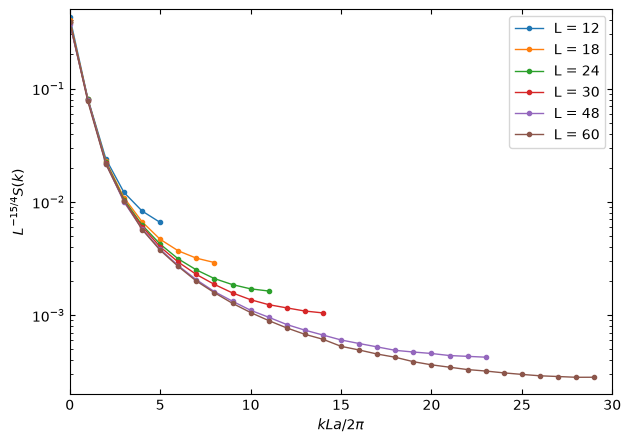

In [29]:
plt.figure(figsize=(7, 5))

for L, mean_S_axis in zip(Ls, mean_S_axes):

    k = 2 * np.pi * np.fft.fftshift(np.fft.fftfreq(L))

    x = k * L / (2 * np.pi)
    y = mean_S_axis * L**(-15/4)

    # paper only needs positive k
    mask = k >= 0

    plt.semilogy(
        x[mask],
        y[mask],
        'o-',
        markersize=3,
        linewidth=1,
        label=f"L = {L}"
    )

plt.xlabel(r"$kLa/2\pi$")
plt.ylabel(r"$L^{-15/4}S(k)$")
plt.xlim(0, 30)
plt.ylim(2e-4, 5e-1)
plt.margins(x=0, y=0)
plt.tick_params(which='both', direction='in', top=True, right=True)
plt.margins(x=0, y=0)
plt.legend()
plt.show()

In [32]:
paper_S0 = {
    12: 0.420,
    18: 0.406,
    24: 0.388,
    30: 0.386,
    48: 0.378,
    60: 0.374
}

for L, mean_S_axis in zip(Ls, mean_S_axes):
    centre = L // 2

    simulated = mean_S_axis[centre] * L**(-15/4)

    print(
        f"L = {L}: "
        f"simulation = {simulated:.3f}, "
        f"paper = {paper_S0[L]:.3f}"
    )

L = 12: simulation = 0.429, paper = 0.420
L = 18: simulation = 0.403, paper = 0.406
L = 24: simulation = 0.387, paper = 0.388
L = 30: simulation = 0.388, paper = 0.386
L = 48: simulation = 0.374, paper = 0.378
L = 60: simulation = 0.388, paper = 0.374
